# 实验四 多层感知机手写数字识别
按顺序运行全部单元格即可复现实验。训练集为 60000 张，测试集为 10000 张。
基础模型采用参考 PDF 的参数，再对比学习率 0.1 的 MLP 与 LeNet。三组均训练 30 轮。详细分析见仓库首页。


## 1. 环境与参数


In [1]:
from pathlib import Path
import csv
import json
import platform
import random
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision.datasets import MNIST

ROOT = Path.cwd()
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed, batch_size, epochs = 42, 2048, 30
print(f"Python {platform.python_version()}")
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"设备 {device} | 批量 {batch_size} | 轮数 {epochs} | 随机种子 {seed}")



Python 3.13.7
PyTorch 2.11.0+cpu | torchvision 0.26.0+cpu
设备 cpu | 批量 2048 | 轮数 30 | 随机种子 42


## 2. 数据读取与样本展示


训练集: (60000, 28, 28)
测试集: (10000, 28, 28)
输入像素范围: 0.0 1.0


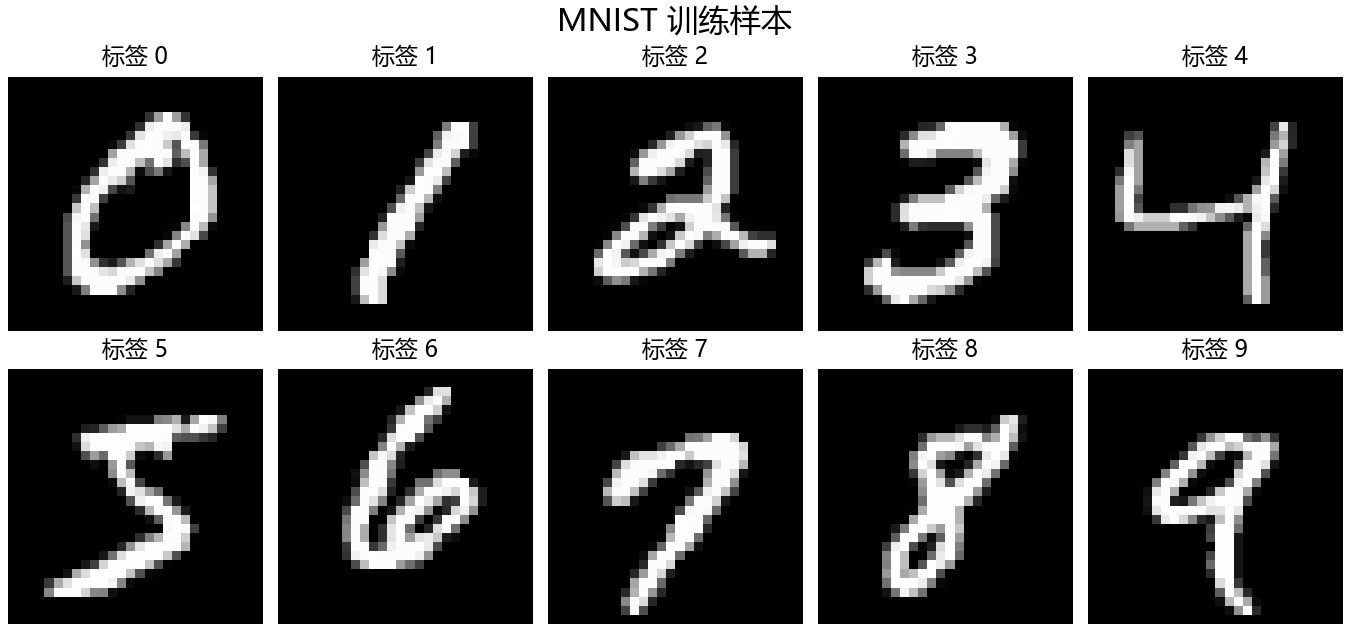

In [2]:
train_data = MNIST(ROOT / "data", train=True, download=True)
test_data = MNIST(ROOT / "data", train=False, download=True)
# 与 ToTensor 对灰度图的处理一致，将像素除以 255
x_train = train_data.data.reshape(-1, 784).float() / 255.0
x_test = test_data.data.reshape(-1, 784).float() / 255.0
y_train, y_test = train_data.targets, test_data.targets
train_set = TensorDataset(x_train, y_train)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=batch_size, shuffle=False)
print("训练集:", tuple(train_data.data.shape))
print("测试集:", tuple(test_data.data.shape))
print("输入像素范围:", x_train.min().item(), x_train.max().item())

fig, axes = plt.subplots(2, 5, figsize=(9, 4.2), layout="constrained")
for digit, ax in enumerate(axes.flat):
    index = torch.where(y_train == digit)[0][0].item()
    ax.imshow(train_data.data[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"标签 {digit}", fontsize=11)
    ax.axis("off")
fig.suptitle("MNIST 训练样本", fontsize=15)
fig.savefig(OUT / "samples.png", dpi=150)
plt.close(fig)



## 3. 模型与评估函数


In [3]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Linear(784, 128)
        self.l2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.l1(x))
        return self.l2(x)


class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.c5 = nn.Conv2d(16, 120, kernel_size=5)
        self.pool = nn.AvgPool2d(2, 2)
        self.f6 = nn.Linear(120, 84)
        self.output = nn.Linear(84, 10)

    def forward(self, x):
        # 将相同的 28 × 28 图像补零到 LeNet 使用的 32 × 32
        x = F.pad(x.reshape(-1, 1, 28, 28), (2, 2, 2, 2))
        x = self.pool(torch.tanh(self.c1(x)))
        x = self.pool(torch.tanh(self.c3(x)))
        x = torch.tanh(self.c5(x)).flatten(1)
        x = torch.tanh(self.f6(x))
        return self.output(x)


@torch.no_grad()
def evaluate(model):
    model.eval()
    loss_sum, correct = 0.0, 0
    predictions = []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        output = model(x)
        loss_sum += F.cross_entropy(output, y, reduction="sum").item()
        pred = output.argmax(dim=1)
        correct += (pred == y).sum().item()
        predictions.append(pred.cpu())
    return loss_sum / len(y_test), correct / len(y_test), torch.cat(predictions)


print(MLP())
print("MLP 参数量:", sum(p.numel() for p in MLP().parameters()))
print(LeNet())
print("LeNet 参数量:", sum(p.numel() for p in LeNet().parameters()))



MLP(
  (l1): Linear(in_features=784, out_features=128, bias=True)
  (l2): Linear(in_features=128, out_features=10, bias=True)
)
MLP 参数量: 101770
LeNet(
  (c1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (c5): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (output): Linear(in_features=84, out_features=10, bias=True)
)
LeNet 参数量: 61706


## 4. 三组训练与测试


In [4]:
history, summary, all_predictions = [], [], {}
experiments = [("基础模型", MLP, 0.01, "confusion_lr0.01.csv"),
               ("调整学习率", MLP, 0.1, "confusion_lr0.1.csv"),
               ("LeNet", LeNet, 0.1, "confusion_lenet.csv")]
for name, model_class, lr, cm_file in experiments:
    # 三组每轮样本顺序一致，两组 MLP 的初始权重也相同
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, generator=generator)
    model = model_class().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    start = time.perf_counter()
    print(f"\n{name}，学习率 {lr}")
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            output = model(x)
            loss = F.cross_entropy(output, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
        train_loss = loss_sum / len(train_set)
        history.append({"model": name, "lr": lr, "epoch": epoch, "train_loss": train_loss})
        print(f"第 {epoch:02d} 轮 | 训练损失 {train_loss:.6f}", flush=True)
    test_loss, accuracy, pred = evaluate(model)
    seconds = time.perf_counter() - start
    cm = torch.bincount(y_test * 10 + pred, minlength=100).reshape(10, 10).numpy()
    np.savetxt(OUT / cm_file, cm, delimiter=",", fmt="%d")
    all_predictions[name] = pred.numpy()
    summary.append({"model": name, "lr": lr, "epochs": epochs,
                    "parameters": sum(p.numel() for p in model.parameters()),
                    "train_loss": train_loss, "test_loss": test_loss,
                    "accuracy": accuracy, "correct": int((pred == y_test).sum()),
                    "errors": int((pred != y_test).sum()), "seconds": seconds})
    print(f"测试损失 {test_loss:.6f} | 准确率 {accuracy:.2%} | 错分 {summary[-1]['errors']} 张")

for filename, rows in [("history.csv", history), ("summary.csv", summary)]:
    with (OUT / filename).open("w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
np.savez_compressed(OUT / "predictions.npz", labels=y_test.numpy(),
                    baseline=all_predictions["基础模型"], adjusted=all_predictions["调整学习率"],
                    lenet=all_predictions["LeNet"])
environment = {"python": platform.python_version(), "torch": torch.__version__,
               "torchvision": torchvision.__version__, "numpy": np.__version__,
               "matplotlib": matplotlib.__version__, "device": str(device),
               "seed": seed, "batch_size": batch_size, "epochs": epochs,
               "train_samples": len(y_train), "test_samples": len(y_test),
               "normalization": "像素除以 255", "threads": torch.get_num_threads(),
               "lenet_input": "28 × 28 图像四周各补 2 个零到 32 × 32",
               "lenet_variant": "Tanh、平均池化、全通道卷积、线性分类输出"}
(OUT / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")




基础模型，学习率 0.01
第 01 轮 | 训练损失 2.270287
第 02 轮 | 训练损失 2.212241
第 03 轮 | 训练损失 2.147215
第 04 轮 | 训练损失 2.073479
第 05 轮 | 训练损失 1.990719
第 06 轮 | 训练损失 1.899865
第 07 轮 | 训练损失 1.802614
第 08 轮 | 训练损失 1.701549
第 09 轮 | 训练损失 1.599593
第 10 轮 | 训练损失 1.499528
第 11 轮 | 训练损失 1.403707
第 12 轮 | 训练损失 1.314228
第 13 轮 | 训练损失 1.232137
第 14 轮 | 训练损失 1.157890
第 15 轮 | 训练损失 1.091349
第 16 轮 | 训练损失 1.032057
第 17 轮 | 训练损失 0.979341
第 18 轮 | 训练损失 0.932439
第 19 轮 | 训练损失 0.890631
第 20 轮 | 训练损失 0.853368
第 21 轮 | 训练损失 0.819931
第 22 轮 | 训练损失 0.789883
第 23 轮 | 训练损失 0.762787
第 24 轮 | 训练损失 0.738227
第 25 轮 | 训练损失 0.715882
第 26 轮 | 训练损失 0.695569
第 27 轮 | 训练损失 0.676932
第 28 轮 | 训练损失 0.659820
第 29 轮 | 训练损失 0.644023
第 30 轮 | 训练损失 0.629462
测试损失 0.599499 | 准确率 86.26% | 错分 1374 张

调整学习率，学习率 0.1
第 01 轮 | 训练损失 1.950240
第 02 轮 | 训练损失 1.111535
第 03 轮 | 训练损失 0.720295
第 04 轮 | 训练损失 0.571800
第 05 轮 | 训练损失 0.496404
第 06 轮 | 训练损失 0.450896
第 07 轮 | 训练损失 0.420297
第 08 轮 | 训练损失 0.398267
第 09 轮 | 训练损失 0.381286
第 10 轮 | 训练损失 0.367802
第 11 轮 | 训练

## 5. 损失曲线与混淆矩阵


已保存损失曲线与两组混淆矩阵


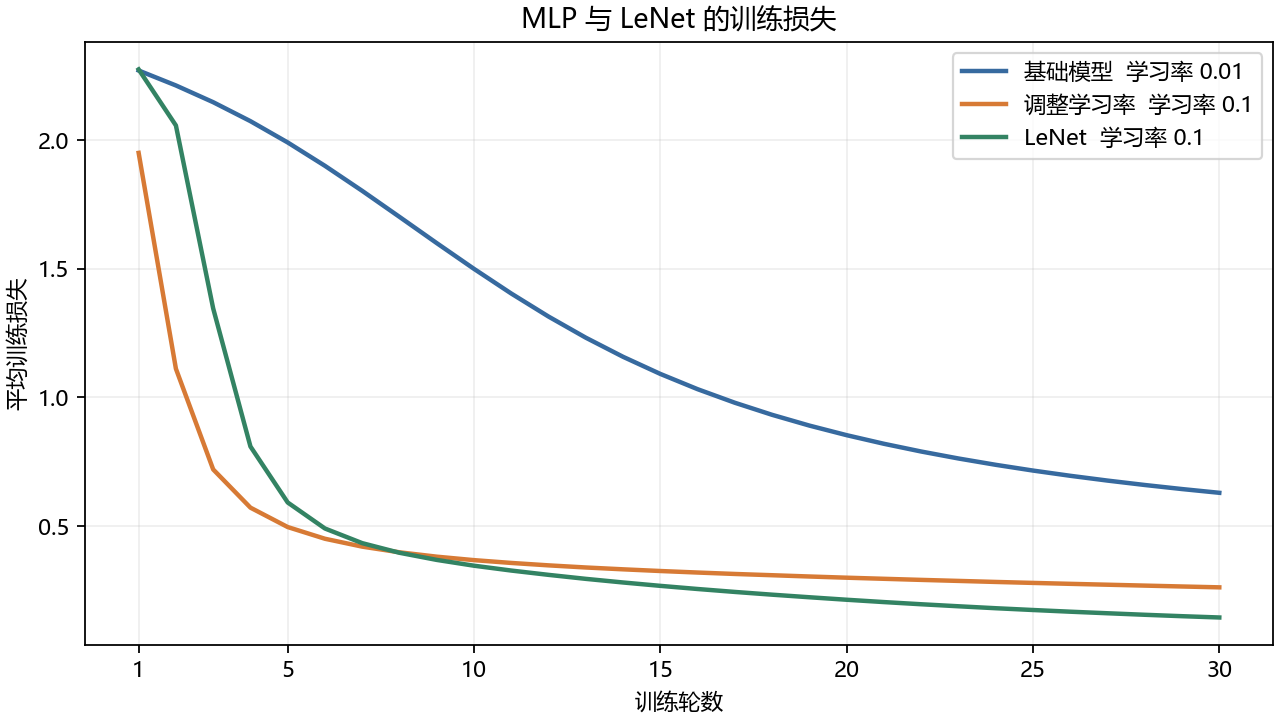

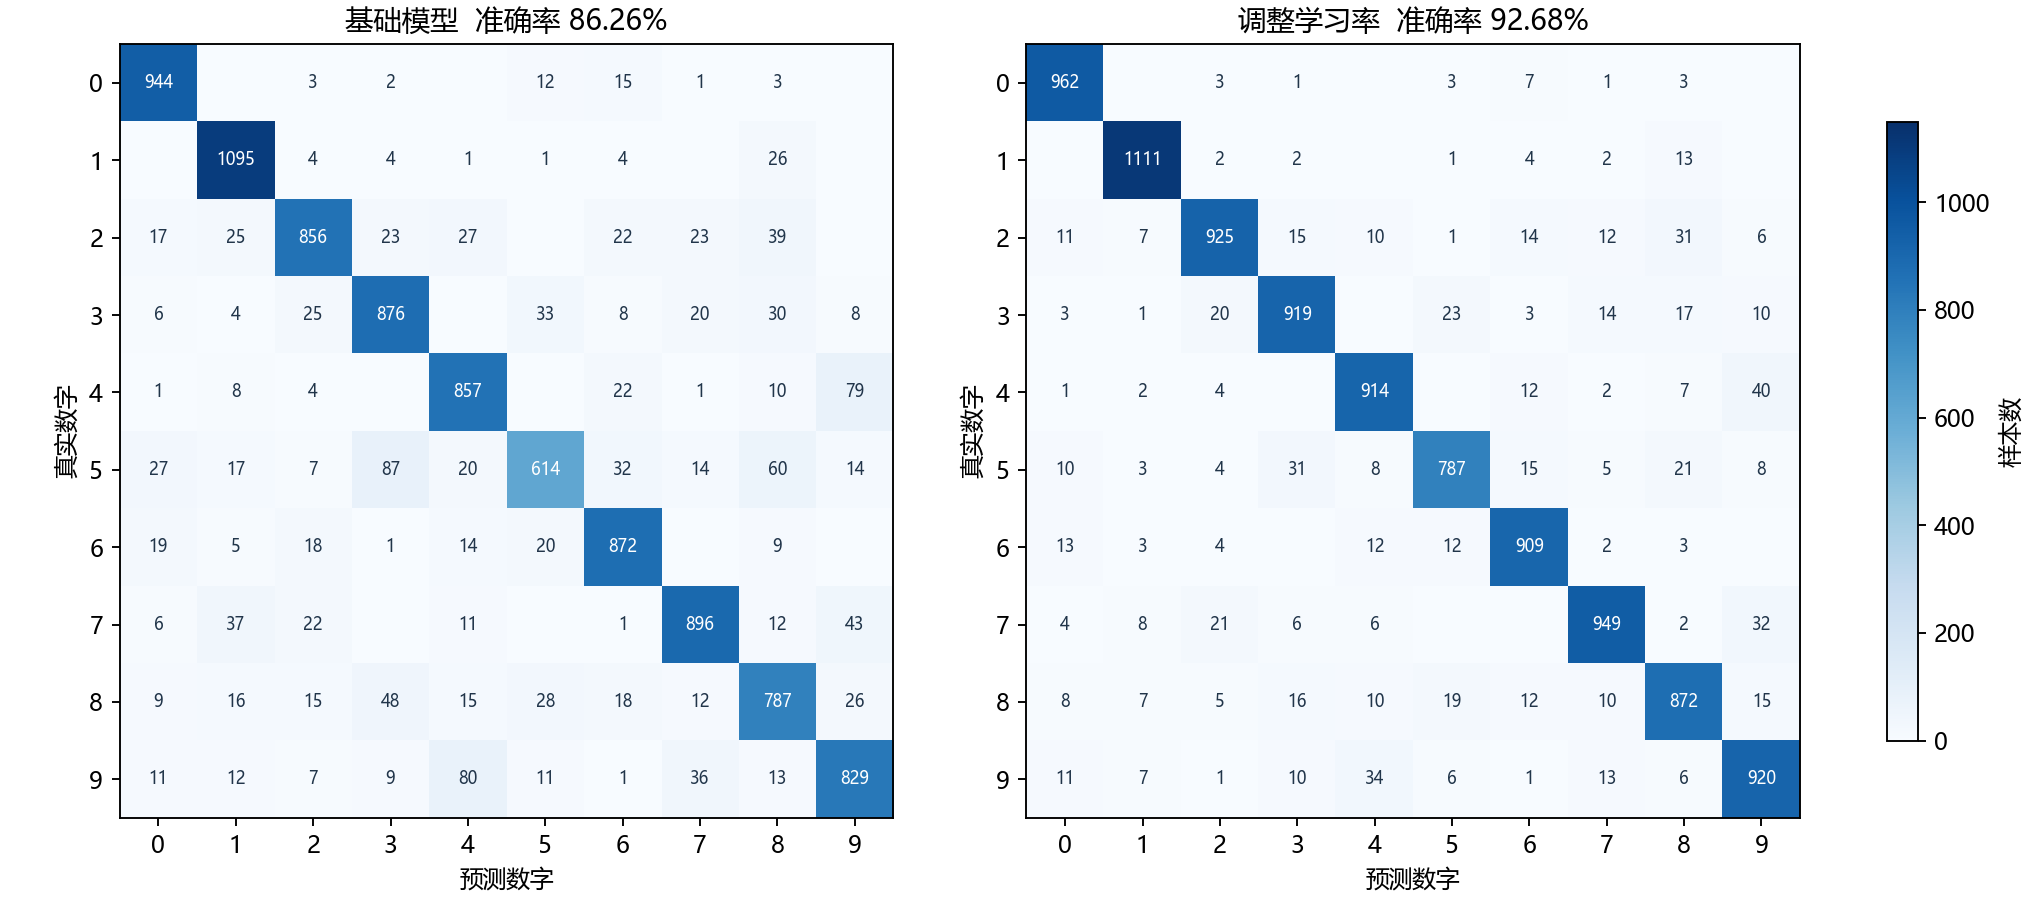

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for name, color in [("基础模型", "#376a9f"), ("调整学习率", "#d77a35"),
                    ("LeNet", "#338363")]:
    rows = [r for r in history if r["model"] == name]
    ax.plot([r["epoch"] for r in rows], [r["train_loss"] for r in rows],
            label=f"{name}  学习率 {rows[0]['lr']}", color=color, linewidth=2)
ax.set(xlabel="训练轮数", ylabel="平均训练损失", title="MLP 与 LeNet 的训练损失")
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(OUT / "loss_curve.png", dpi=160)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.3), layout="constrained")
for ax, row in zip(axes, summary[:2]):
    pred = all_predictions[row["model"]]
    cm = np.bincount(y_test.numpy() * 10 + pred, minlength=100).reshape(10, 10)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1150)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 575 else "#21354a")
    ax.set(xticks=range(10), yticks=range(10), xlabel="预测数字", ylabel="真实数字",
           title=f"{row['model']}  准确率 {row['accuracy']:.2%}")
fig.colorbar(im, ax=axes, shrink=0.8, label="样本数")
fig.savefig(OUT / "confusion_matrix.png", dpi=170)
plt.close(fig)
print("已保存损失曲线与两组混淆矩阵")



## 6. 预测示例与错分样本


前 10 个错分样本的序号: [8, 33, 77, 92, 124, 149, 193, 195, 217, 233]


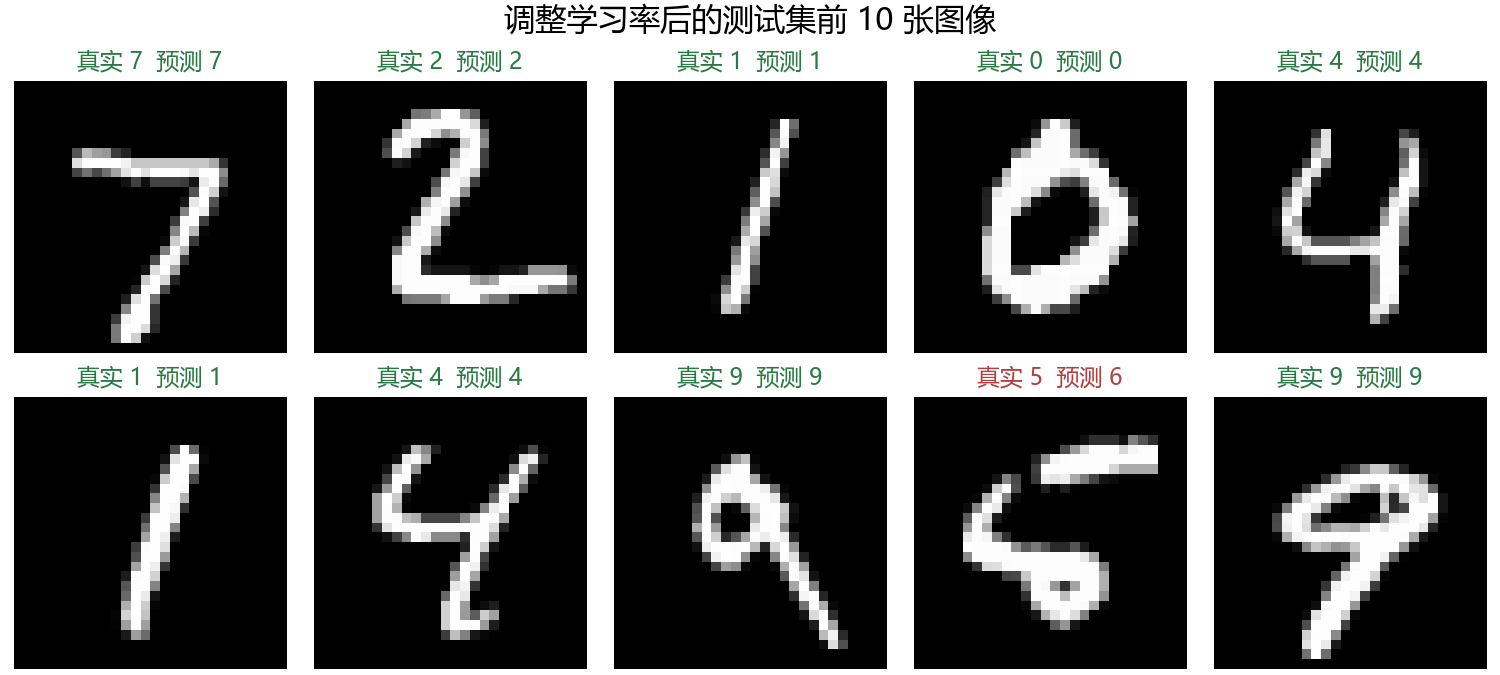

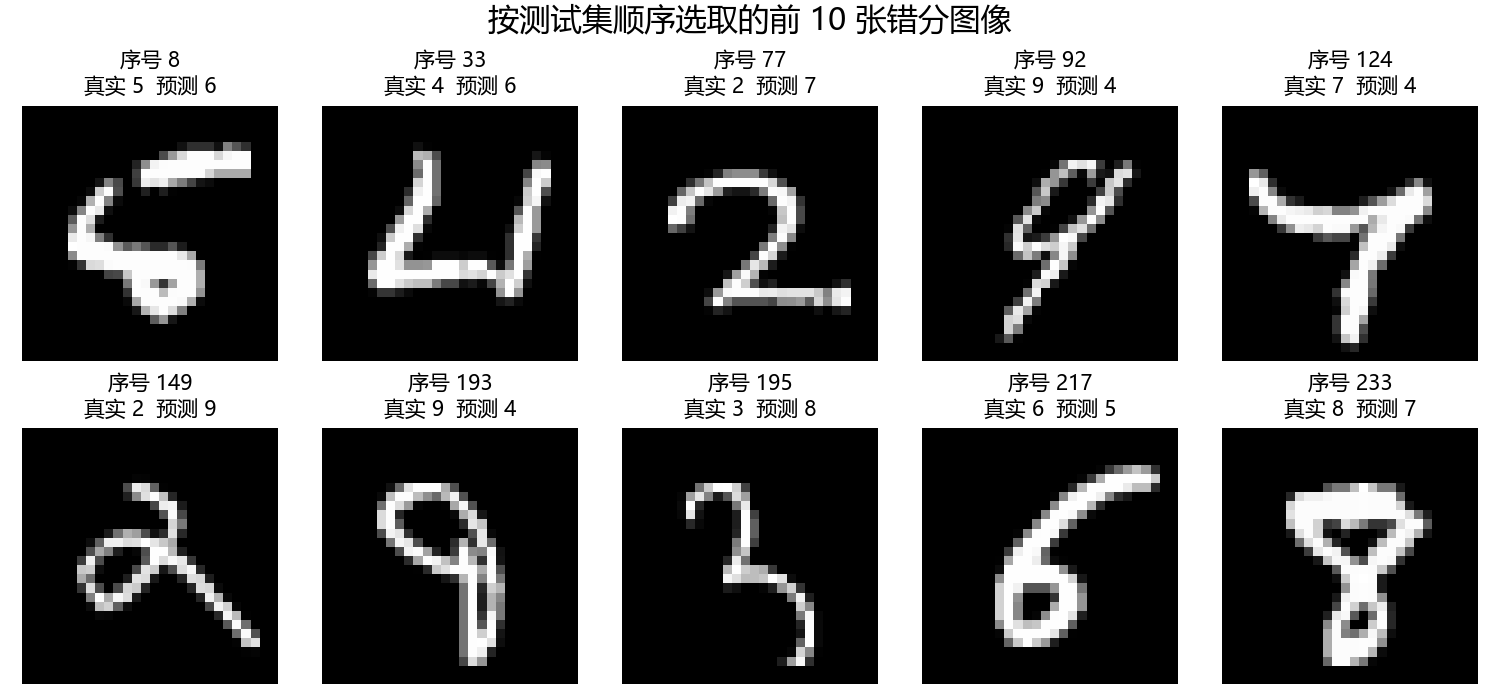

In [6]:
adjusted = all_predictions["调整学习率"]
labels = y_test.numpy()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5), layout="constrained")
for index, ax in enumerate(axes.flat):
    ax.imshow(test_data.data[index], cmap="gray", vmin=0, vmax=255)
    color = "#287a42" if adjusted[index] == labels[index] else "#b43e3e"
    ax.set_title(f"真实 {labels[index]}  预测 {adjusted[index]}", color=color, fontsize=11)
    ax.axis("off")
fig.suptitle("调整学习率后的测试集前 10 张图像", fontsize=15)
fig.savefig(OUT / "predictions.png", dpi=150)
plt.close(fig)

wrong = np.flatnonzero(adjusted != labels)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.6), layout="constrained")
for ax, index in zip(axes.flat, wrong[:10]):
    ax.imshow(test_data.data[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"序号 {index}\n真实 {labels[index]}  预测 {adjusted[index]}", fontsize=10)
    ax.axis("off")
for ax in axes.flat[min(10, len(wrong)):]:
    ax.axis("off")
fig.suptitle("按测试集顺序选取的前 10 张错分图像", fontsize=15)
fig.savefig(OUT / "errors.png", dpi=150)
plt.close(fig)
print("前 10 个错分样本的序号:", wrong[:10].tolist())



## 7. LeNet 对比图与样本分析


MLP 错分、LeNet 正确: 386
MLP 正确、LeNet 错分: 47
两者均错分: 346
LeNet 修正的前 10 个序号: [8, 77, 92, 124, 193, 195, 217, 233, 245, 300]
实验完成，数据已保存在 results 目录


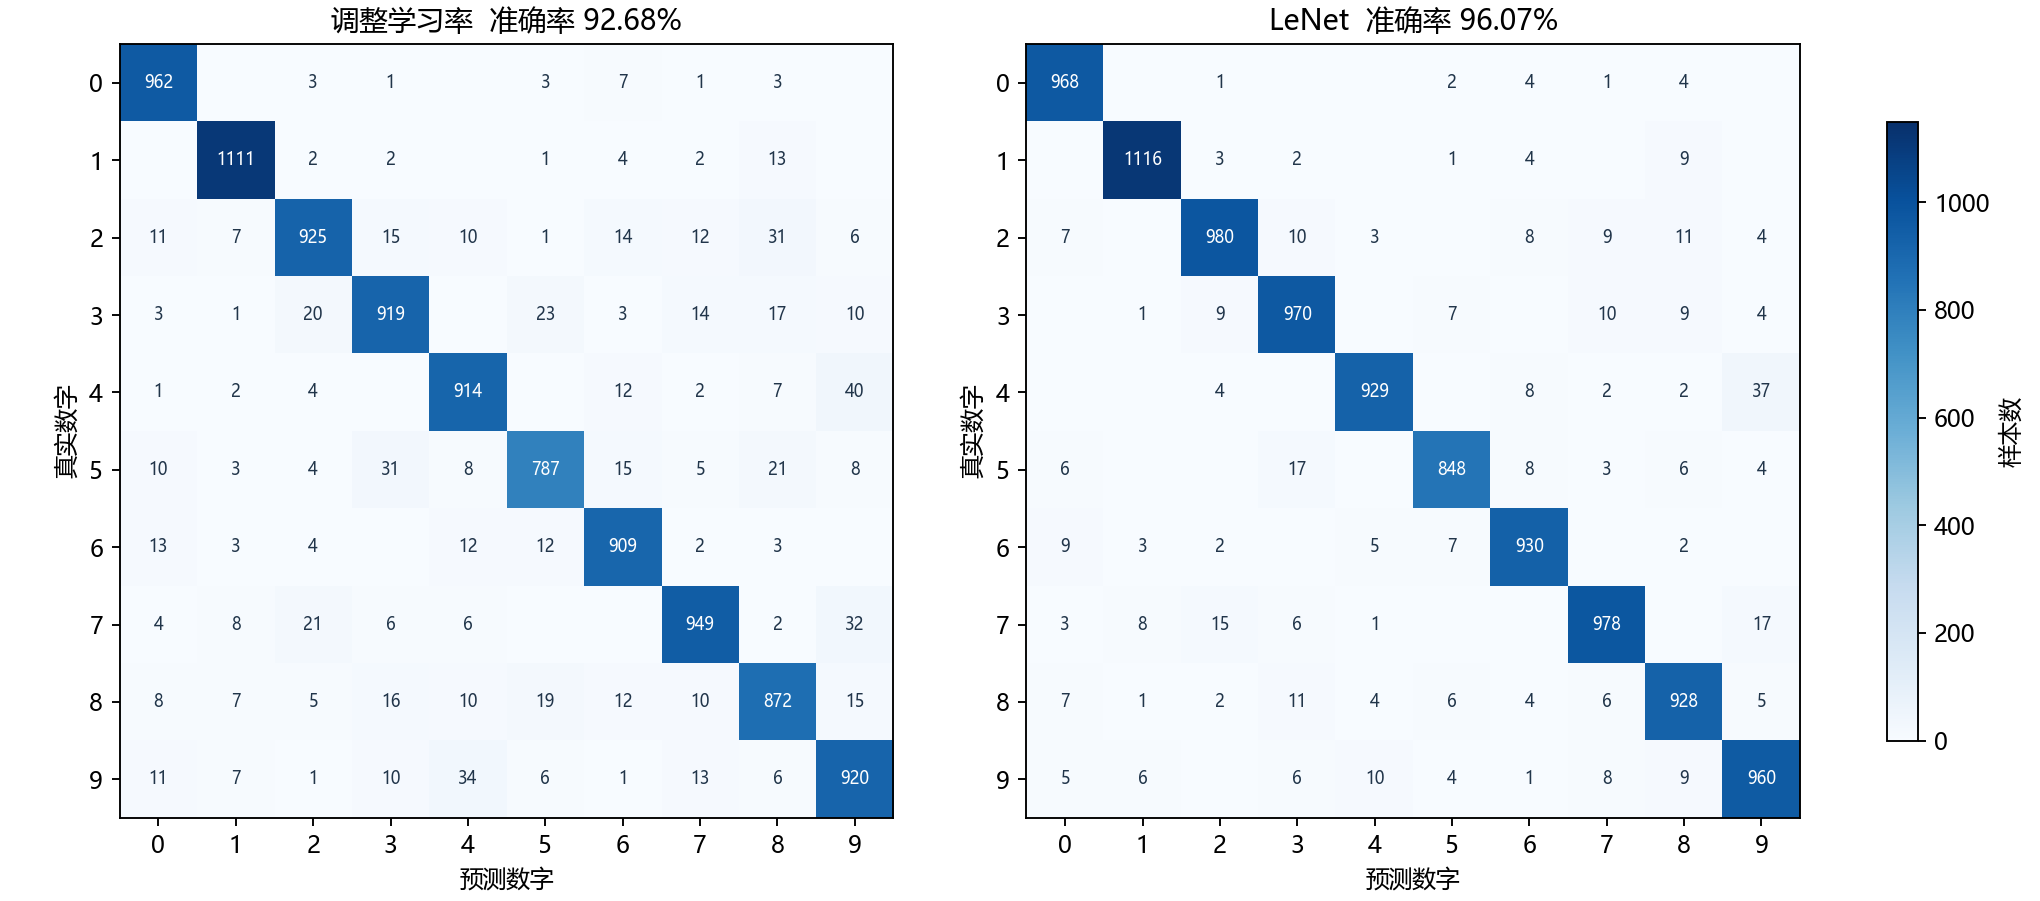

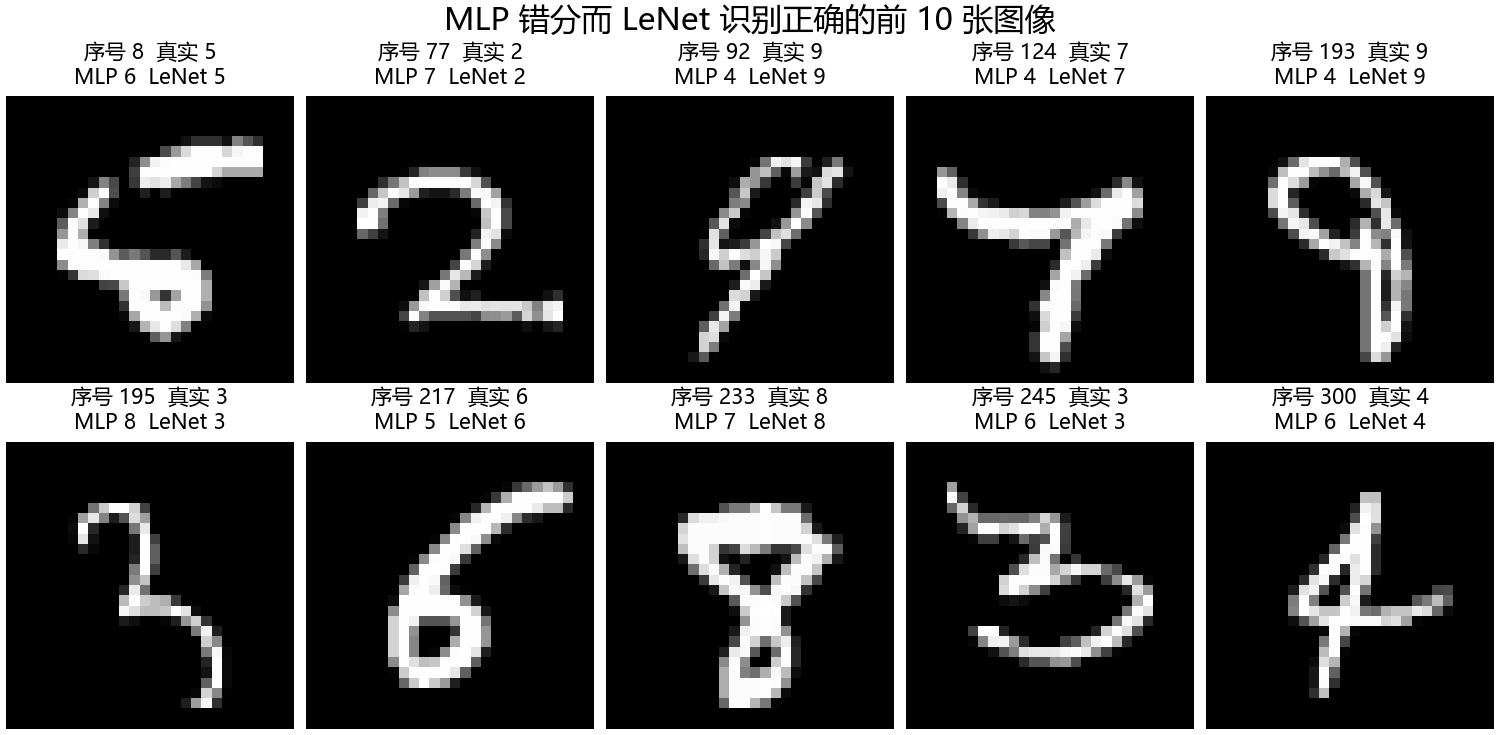

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3), layout="constrained")
for ax, row in zip(axes, summary[1:]):
    pred = all_predictions[row["model"]]
    cm = np.bincount(labels * 10 + pred, minlength=100).reshape(10, 10)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1150)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 575 else "#21354a")
    ax.set(xticks=range(10), yticks=range(10), xlabel="预测数字", ylabel="真实数字",
           title=f"{row['model']}  准确率 {row['accuracy']:.2%}")
fig.colorbar(im, ax=axes, shrink=0.8, label="样本数")
fig.savefig(OUT / "lenet_comparison.png", dpi=170)
plt.close(fig)

lenet_pred = all_predictions["LeNet"]
corrected = np.flatnonzero((adjusted != labels) & (lenet_pred == labels))
regressed = np.flatnonzero((adjusted == labels) & (lenet_pred != labels))
both_wrong = np.flatnonzero((adjusted != labels) & (lenet_pred != labels))
fig, axes = plt.subplots(2, 5, figsize=(10, 4.9), layout="constrained")
for ax, index in zip(axes.flat, corrected[:10]):
    ax.imshow(test_data.data[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"序号 {index}  真实 {labels[index]}\nMLP {adjusted[index]}  LeNet {lenet_pred[index]}", fontsize=10)
    ax.axis("off")
for ax in axes.flat[min(10, len(corrected)):]:
    ax.axis("off")
fig.suptitle("MLP 错分而 LeNet 识别正确的前 10 张图像", fontsize=15)
fig.savefig(OUT / "lenet_examples.png", dpi=150)
plt.close(fig)
comparison = {"mlp_wrong_lenet_correct": len(corrected),
              "mlp_correct_lenet_wrong": len(regressed), "both_wrong": len(both_wrong),
              "corrected_first10": corrected[:10].tolist(),
              "regressed_first10": regressed[:10].tolist()}
(OUT / "lenet_comparison.json").write_text(json.dumps(comparison, ensure_ascii=False, indent=2), encoding="utf-8")
print("MLP 错分、LeNet 正确:", len(corrected))
print("MLP 正确、LeNet 错分:", len(regressed))
print("两者均错分:", len(both_wrong))
print("LeNet 修正的前 10 个序号:", corrected[:10].tolist())
print("实验完成，数据已保存在 results 目录")
